# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name_: Castaneda, Joaquin 
- _Student No._: 2024-09743
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![exe11_problem1.png](exe11_problem1.png)

Figure 1. Absolute error versus number of intervals/samples for each integration method, and Monte Carlo sample points under the curve (blue: above the x-axis, red: below), for Functions 1 to 3.

### Report discussion

In the left column (error plots), Monte Carlo has the largest error for all three functions and also fluctuates (instead of decreasing steadily), which ends at about 10⁻² to 10⁻¹ at N ≈ 10⁴; whereas, the trapezoidal rule (and Simpson’s rules in Functions 1 and 3) falls along nearly straight lines on the log-log axes, which ends at about 10⁻⁷ to 10⁻⁶. This is because Monte Carlo’s error scales as 1/√N and also depends on the random draw. For Functions 1 and 3, both Simpson’s lines go parallel to the trapezoidal line and are below it by a constant factor, hence, they are more accurate (but converge at about the same rate). For Function 2, both Simpson’s errors stay near 10⁻¹⁵ for all N (Simpson’s 1/3 drops off the plot at two N values, wherein, its error is exactly zero), because Function 2 is a quadratic, which Simpson’s rules integrate exactly, so only round-off error remains, whereas, the trapezoidal error keeps decreasing. In the right column, only the sampled points between the curve and the x-axis are shown, blue above and red below: Function 1 is all blue, Function 2 is blue for |x| < 1 and red for 1 < |x| ≤ 2, and Function 3 is blue for x below about π/2 and red beyond it.

Monte Carlo integration works because the average of many random samples approaches the average value of the function, which allows us to estimate the integral. Newton-Cotes methods are generally faster and more accurate for smooth & continuous functions, moreover, (unlike Monte Carlo) they give out deterministic results. Monte Carlo is more useful for high-dimensional integrals for the reason that its convergence rate does not depend on dimensionality.

### Reflection

I hope I will be able to use Monte Carlo soon as an analyst.


---
## Section 2: Code

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy as sc
import pandas as pd

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



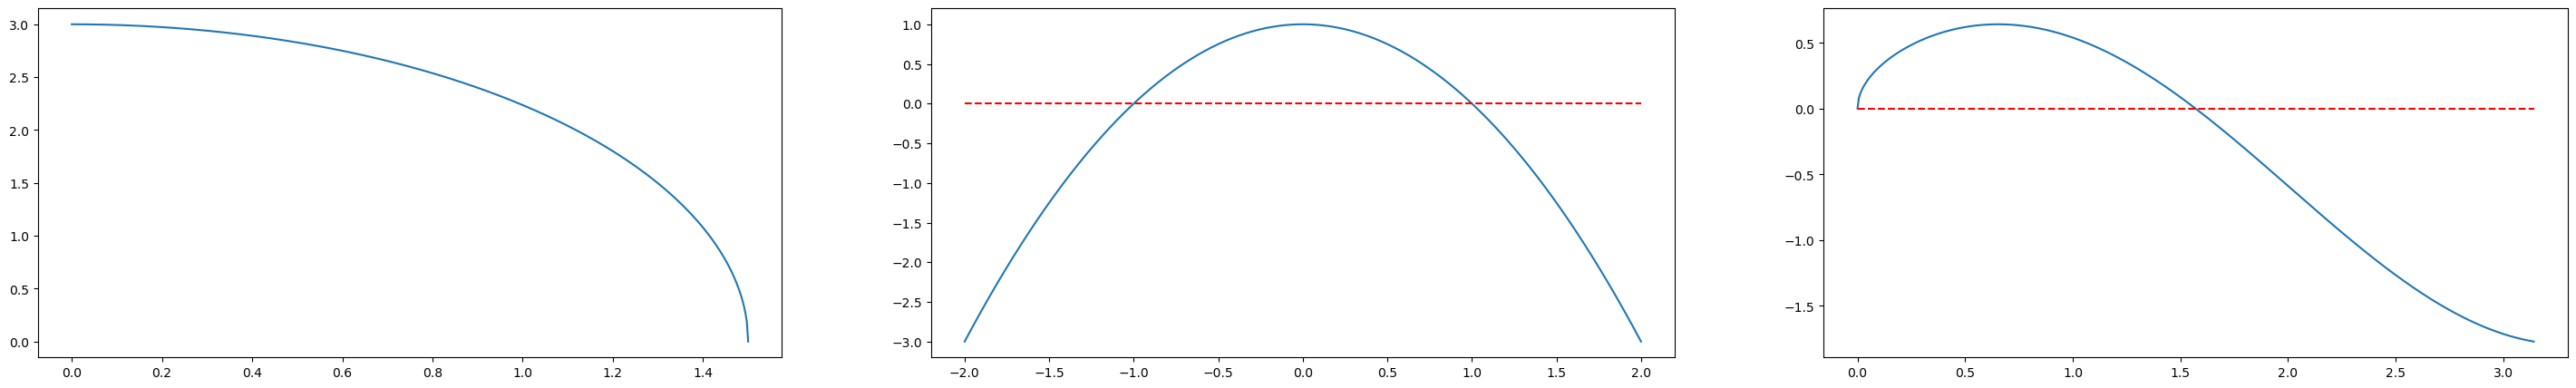

In [7]:
# Make test functions and a function for generating evenly spaced points

def domain(a, b, n=500):
    return np.linspace(a, b, n)  # Gawa n points between a and b

def func_1(x):
    return np.sqrt(9 - 4*x**2)  # Upper half of ellipse

def func_2(x):
    return 1 - x**2  # parabola pababa

def func_3(x):
    return np.cos(x)*np.sqrt(x)  # Cosine mult. by sqrt

# Gawa domains for each function
x1 = domain(0, 1.5)
x2 = domain(-2, 2)
x3 = domain(0, np.pi)

# Plot the test functions
fig, axes = plt.subplots(1, 3, figsize=(36, 5))

axes[0].plot(x1, func_1(x1))
axes[1].plot(x2, func_2(x2))
axes[1].plot(x2, np.zeros_like(x2), 'r--')  # Plot yung horizontal zero line
axes[2].plot(x3, func_3(x3))
axes[2].plot(x3, np.zeros_like(x3), 'r--')  # Plot yung horizontal zero line

In [17]:
# Define numerical integration methods

def monte_carlo(f, a, b, total=False, n=500):
    x = np.random.uniform(a, b, n) # Ito ung maggawa n random points
    y = f(x) if not total else np.abs(f(x))
    return (b - a) * np.mean(y)


def trapezoid(f, a, b, total=False, n=50):
    x = domain(a, b, n + 1)
    y = f(x) if not total else np.abs(f(x))
    return (b - a) / (2*n) * np.sum(y[:-1] + y[1:])


def simpson_13(f, a, b, total=False, n=100):
    if n % 2:
        raise ValueError("n must be even.")

    x = domain(a, b, n + 1)
    y = f(x) if not total else np.abs(f(x))

    coefficients = np.full(n + 1, 2)
    coefficients[1:-1:2] = 4
    coefficients[[0, -1]] = 1

    return (b - a) / (3*n) * np.sum(coefficients * y)


def simpson_38(f, a, b, total=False, n=102):
    if n % 3:
        raise ValueError("n must be divisible by 3.")

    x = domain(a, b, n + 1)
    y = f(x) if not total else np.abs(f(x))

    coefficients = np.full(n + 1, 3)
    coefficients[3:-1:3] = 2
    coefficients[[0, -1]] = 1

    return 3 * (b - a) / (8*n) * np.sum(coefficients * y)


# Pang check, we use scipy

def compare_methods(f, a, b):
    methods = [monte_carlo, trapezoid, simpson_13, simpson_38]
    names = ["Monte Carlo", "Trapezoidal", "Simpson 1/3", "Simpson 3/8"]
    counts = [100000, 100, 100, 102]

    signed_ref = sc.integrate.quad(f, a, b)[0]
    total_ref = sc.integrate.quad(lambda x: abs(f(x)), a, b)[0]

    results = []

    for method, name, n in zip(methods, names, counts):
        results.append({"Method": name, "Signed Area": method(f, a, b, n=n), "Total Area": method(f, a, b, total=True, n=n)})

    print(f"\nFunction: {f.__name__}")
    print(f"Scipy signed integral: {signed_ref:.8f}")
    print(f"Scipy total area:      {total_ref:.8f}")

    display(pd.DataFrame(results))


# Test yung functions (all 3)

compare_methods(func_1, 0, 1.5)
compare_methods(func_2, -2, 2)
compare_methods(func_3, 0, np.pi)


Function: func_1
Scipy signed integral: 3.53429174
Scipy total area:      3.53429174


,Method,Signed Area,Total Area
0,Monte Carlo,3.538403,3.534749
1,Trapezoidal,3.532969,3.532969
2,Simpson 1/3,3.533775,3.533775
3,Simpson 3/8,3.533681,3.533681



Function: func_2
Scipy signed integral: -1.33333333
Scipy total area:      4.00000000


,Method,Signed Area,Total Area
0,Monte Carlo,-1.325347,4.009880
1,Trapezoidal,-1.334400,4.000000
2,Simpson 1/3,-1.333333,3.997867
3,Simpson 3/8,-1.333333,4.000000



Function: func_3
Scipy signed integral: -0.89483147
Scipy total area:      2.30290697


,Method,Signed Area,Total Area
0,Monte Carlo,-0.902993,2.307816
1,Trapezoidal,-0.896012,2.301566
2,Simpson 1/3,-0.895283,2.302455
3,Simpson 3/8,-0.895366,2.302373


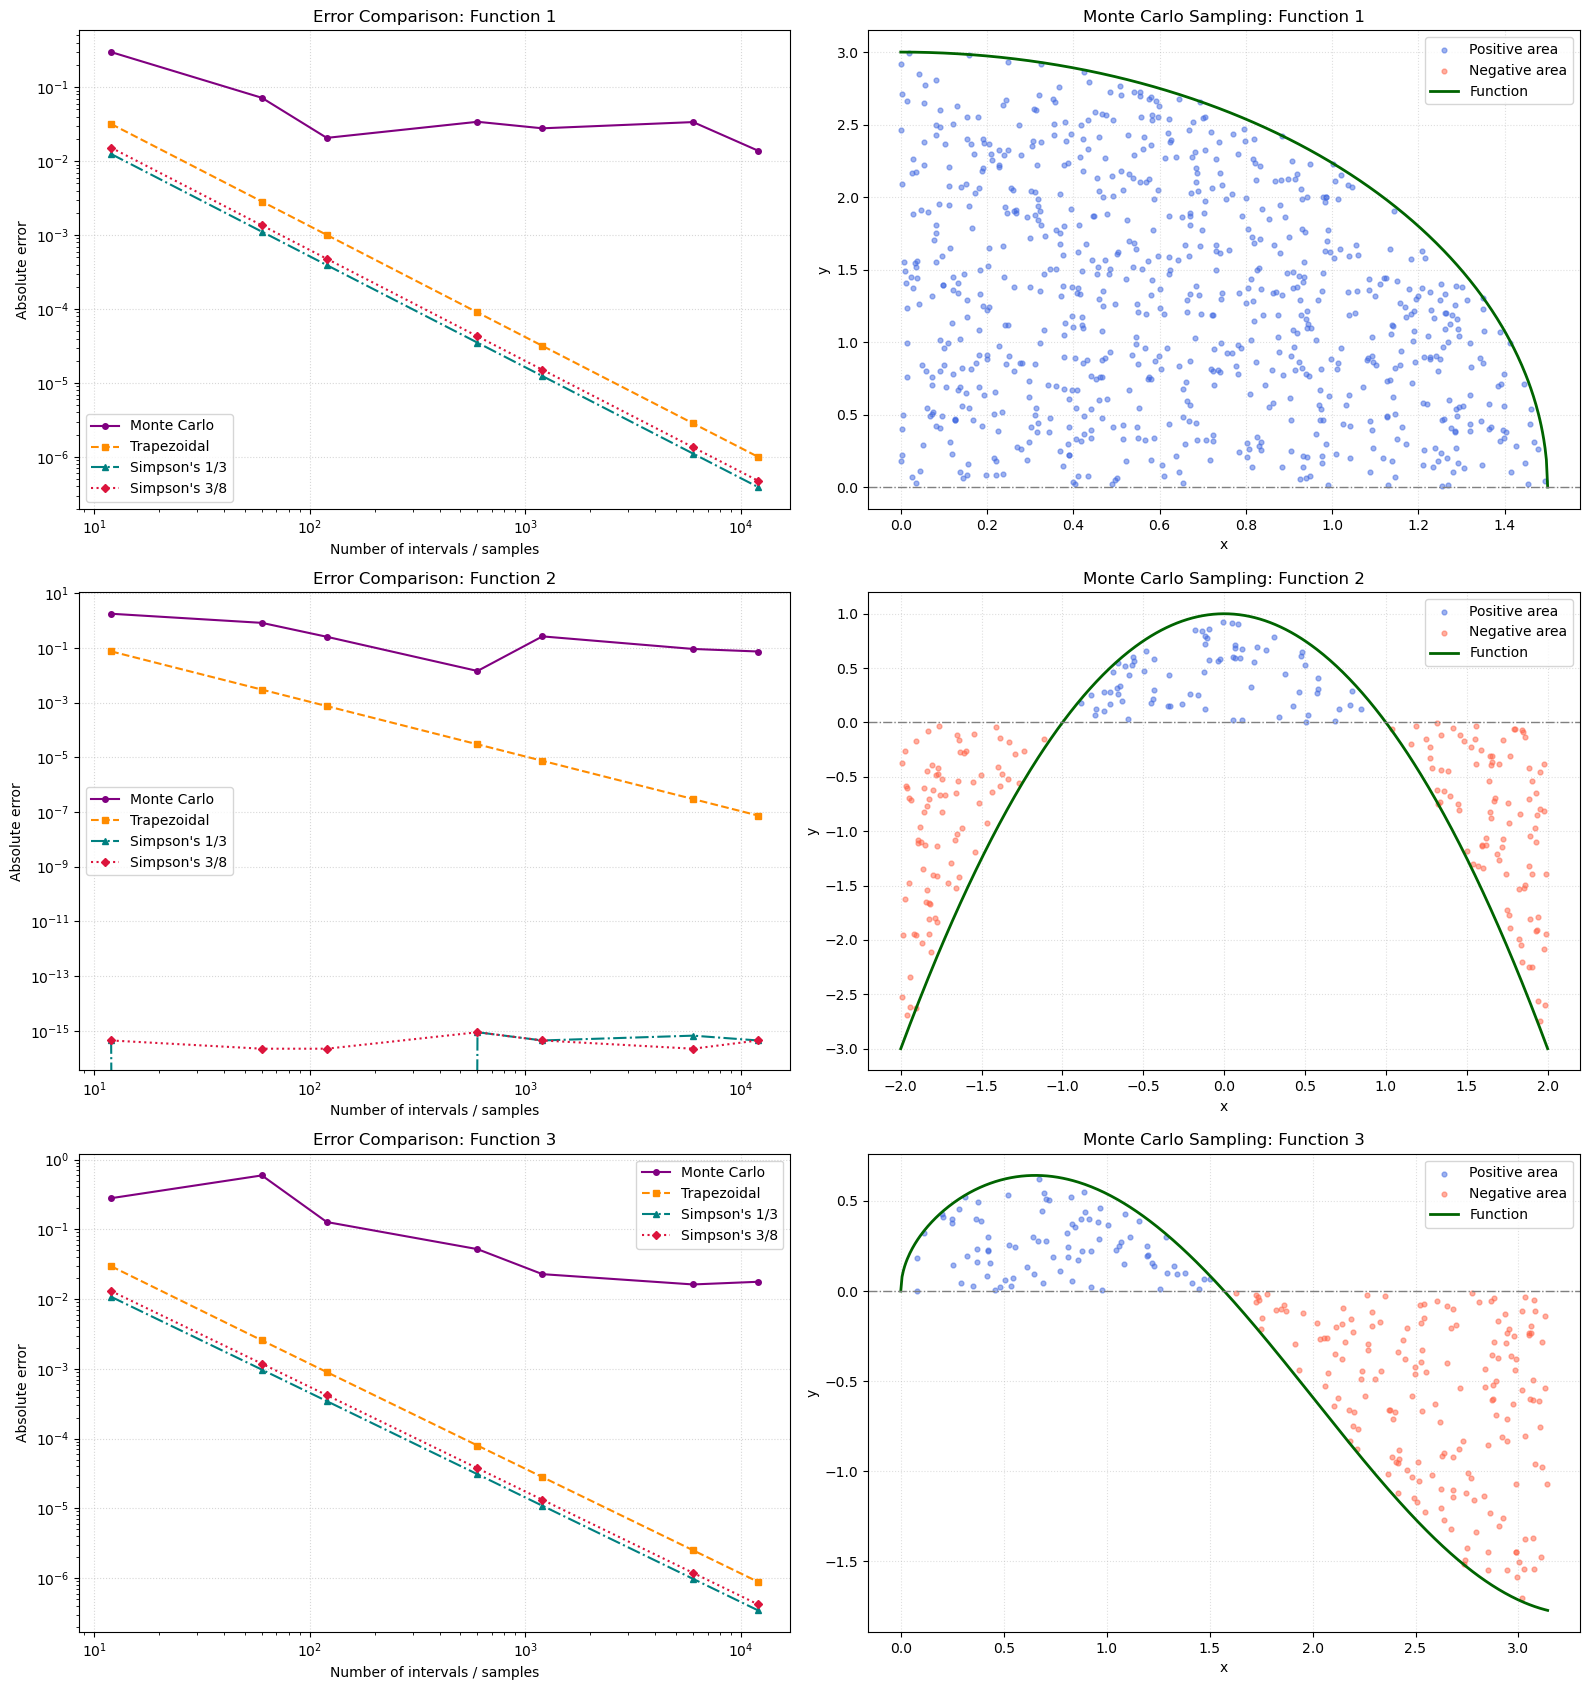

In [16]:
# Gawa six subplots
fig, axes = plt.subplots(3, 2, figsize=(16, 17))

functions = [func_1, func_2, func_3]
domains = [x1, x2, x3]
errors = [err_1, err_2, err_3]
mc_points = [mc_1, mc_2, mc_3]
titles = ["Function 1", "Function 2", "Function 3"]

# Set different colors and line styles
colors = ['purple', 'darkorange', 'teal', 'crimson']
styles = ['-', '--', '-.', ':']

for i in range(3):

    # Plot absolute errors
    error_ax = axes[i, 0]
    error_ax.set_xscale('log')
    error_ax.set_yscale('log')

    error_ax.plot(N, errors[i][0], color=colors[0], linestyle=styles[0], marker='o', markersize=4, label='Monte Carlo')
    error_ax.plot(N, errors[i][1], color=colors[1], linestyle=styles[1], marker='s', markersize=4, label='Trapezoidal')
    error_ax.plot(N, errors[i][2], color=colors[2], linestyle=styles[2], marker='^', markersize=4, label="Simpson's 1/3")
    error_ax.plot(N, errors[i][3], color=colors[3], linestyle=styles[3], marker='D', markersize=4, label="Simpson's 3/8")

    error_ax.set_xlabel("Number of intervals / samples")
    error_ax.set_ylabel("Absolute error")
    error_ax.set_title(f"Error Comparison: {titles[i]}")
    error_ax.legend()
    error_ax.grid(True, linestyle=':', alpha=0.5)

    # Plot Monte Carlo points
    point_ax = axes[i, 1]
    x_random, y_random, above, below = mc_points[i]

    point_ax.scatter(x_random[above], y_random[above], color='royalblue', alpha=0.5, s=12, label='Positive area')

    point_ax.scatter(x_random[below], y_random[below], color='tomato', alpha=0.5, s=12, label='Negative area')

    point_ax.plot(domains[i], functions[i](domains[i]), color='darkgreen', linewidth=2, label='Function')

    point_ax.axhline(0, color='gray', linestyle='-.', linewidth=1)

    point_ax.set_xlabel("x")
    point_ax.set_ylabel("y")
    point_ax.set_title(f"Monte Carlo Sampling: {titles[i]}")
    point_ax.legend()
    point_ax.grid(True, linestyle=':', alpha=0.4)

# Adjust spacing and display
plt.tight_layout()
fig.savefig('exe11_problem1.png', dpi=300)
plt.show()

**End of Notebook.**